# **Section 7: Decision Trees**

In this notebook, I will train and evaluate decision trees. I will start with a basic tree with default parameters, and will then tune the tree complexity (max_depth and min_samples_split) using a cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic decision tree**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
   - 5.1 Load cluster names
   - 5.2 Extract feature importance
   - 5.3 Export biomarkers
6. **Saving model results**


## **1. Importing the data**
Let's import the training and test sets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

sns.set_palette("pastel")

In [2]:
# Load features and labels
snp_train = pd.read_csv("Data/snp_train_selected.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = snp_train.values
y_train = profiles_train.values

X_test = snp_test.values
y_test = profiles_test.values

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (176, 796)
Test set shape: (50, 796)
Categories: [0 1]


## **2. Basic decision tree**

### **2.1 Training and fitting the model**
Let's start with a basic decision tree using default parameters.

In [3]:
# Create Decision Tree
dt = DecisionTreeClassifier(random_state=10)

# Train the model
dt.fit(X_train, y_train)

print("Decision Tree model trained")
print(f"Tree depth: {dt.get_depth()}")
print(f"Number of leaves: {dt.get_n_leaves()}")

Decision Tree model trained
Tree depth: 9
Number of leaves: 33


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training and test sets
accuracy_train = dt.score(X_train, y_train)
accuracy_test = dt.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.9943
Accuracy test set: 0.5200


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = dt.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.70      0.64        30
           1       0.36      0.25      0.29        20

    accuracy                           0.52        50
   macro avg       0.47      0.47      0.47        50
weighted avg       0.49      0.52      0.50        50



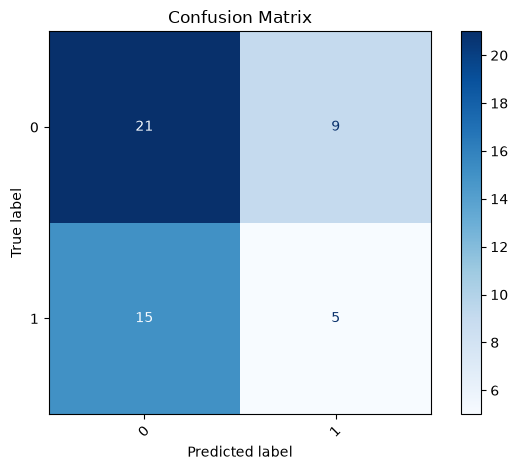

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dt.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

We see that this basic model performs similarly to the K-Nearest neighbors, but doesn't perform particularly well. It also has a similar behavior to the K-Nearest neighbor model, it mainly predicts "susceptible".

## **3. Hyperparameter Tuning: optimizing tree complexity**

Now let's use cross-validated grid search to tune the tree complexity parameters (max_depth and min_samples_split).

### **3.1 Grid search**

In [7]:
# Define parameter grid
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 7, 10],  
    'min_samples_split': [2, 5, 10, 20]
}

# Create grid search
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")


Best parameters: {'max_depth': 7, 'min_samples_split': 2}
Best cross-validation score: 0.6644


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score', 
    'mean_train_score', 'std_train_score',
    'param_max_depth', 'param_min_samples_split'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.602540        0.036989          0.751429         0.007480   
1         0.602540        0.036989          0.751429         0.007480   
2         0.602540        0.036989          0.751429         0.007480   
3         0.602540        0.036989          0.751429         0.007480   
4         0.636349        0.033221          0.828116         0.007171   

   param_max_depth  param_min_samples_split  
0                1                        2  
1                1                        5  
2                1                       10  
3                1                       20  
4                2                        2  


### **3.2 Visualize training/validation curves**

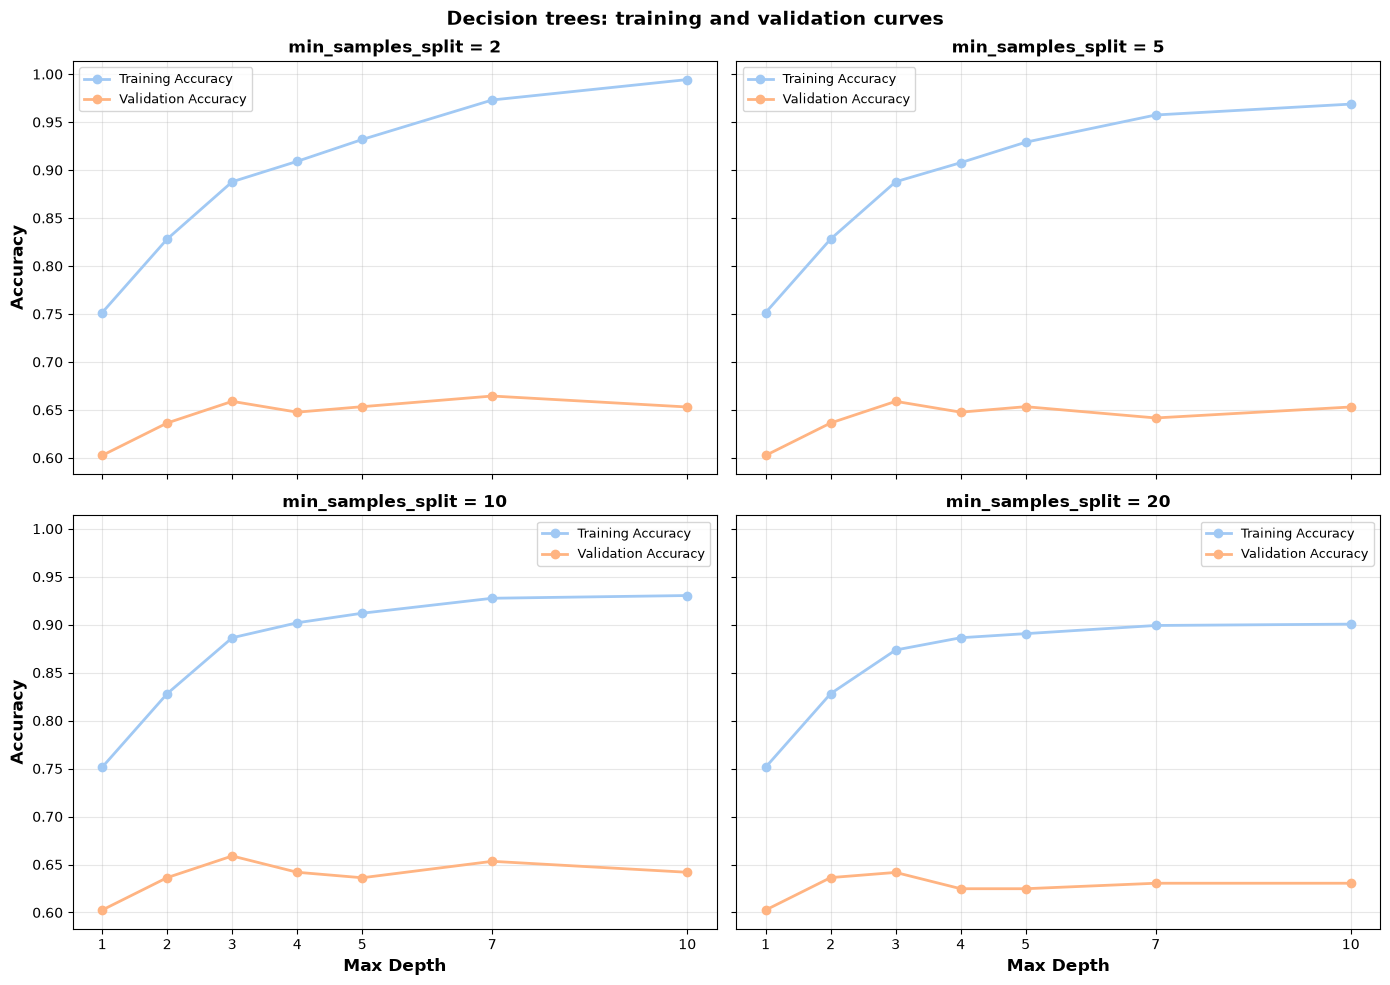

In [9]:
split_values = sorted(cv_results['param_min_samples_split'].unique())
depths = sorted(cv_results['param_max_depth'].unique())

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for ax, split in zip(axes.flat, split_values):
    subset = (cv_results[cv_results['param_min_samples_split'] == split].sort_values('param_max_depth'))
    x = subset['param_max_depth']

    ax.plot(x, subset['mean_train_score'], label='Training Accuracy', marker='o', linewidth=2)
    ax.plot(x, subset['mean_test_score'], label='Validation Accuracy', marker='o', linewidth=2)
    
    ax.set_title(f'min_samples_split = {split}', fontsize=12, fontweight='bold')
    ax.set_xticks(depths)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

for ax in axes[1, :]:
    ax.set_xlabel('Max Depth', fontsize=12, fontweight='bold')
for ax in axes[:, 0]:
    ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')

fig.suptitle('Decision trees: training and validation curves',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("Figures/07_dt_training_curve.png", dpi=300)
plt.show()

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_dt = grid_search.best_estimator_
accuracy_test_best = best_dt.score(X_test, y_test)

print(f"\nBest Model Test Accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")
print(f"Tree depth: {best_dt.get_depth()}")
print(f"Number of leaves: {best_dt.get_n_leaves()}")


Best Model Test Accuracy: 0.5400
Best parameters: {'max_depth': 7, 'min_samples_split': 2}
Best CV score: 0.6644
Tree depth: 7
Number of leaves: 23


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_dt.predict(X_test)

# Classification report
print("\nClassification Report (Best DT):")
print(classification_report(y_test, y_test_pred_best))


Classification Report (Best DT):
              precision    recall  f1-score   support

           0       0.65      0.50      0.57        30
           1       0.44      0.60      0.51        20

    accuracy                           0.54        50
   macro avg       0.55      0.55      0.54        50
weighted avg       0.57      0.54      0.54        50



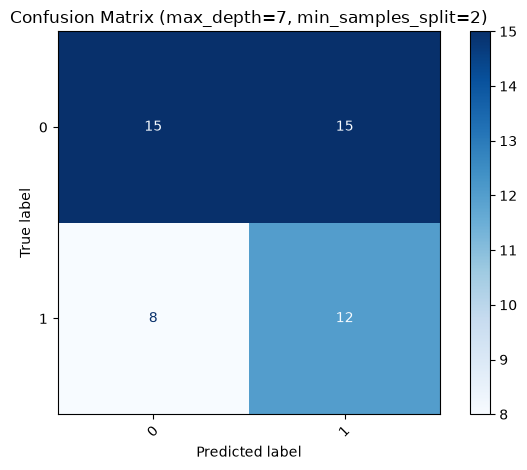

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_dt.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_dt.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (max_depth={grid_search.best_params_['max_depth']}, min_samples_split={grid_search.best_params_['min_samples_split']})")
plt.tight_layout()
plt.savefig("Figures/07_dt_cm.png", dpi=300)
plt.show()

We see that hyperparameter optimization didn't increase performance of the model in comparison to the basic model. In conclusion, decision trees also do not seem to perform well on this data. 

### **4.3 ROC Curve and AUC score**

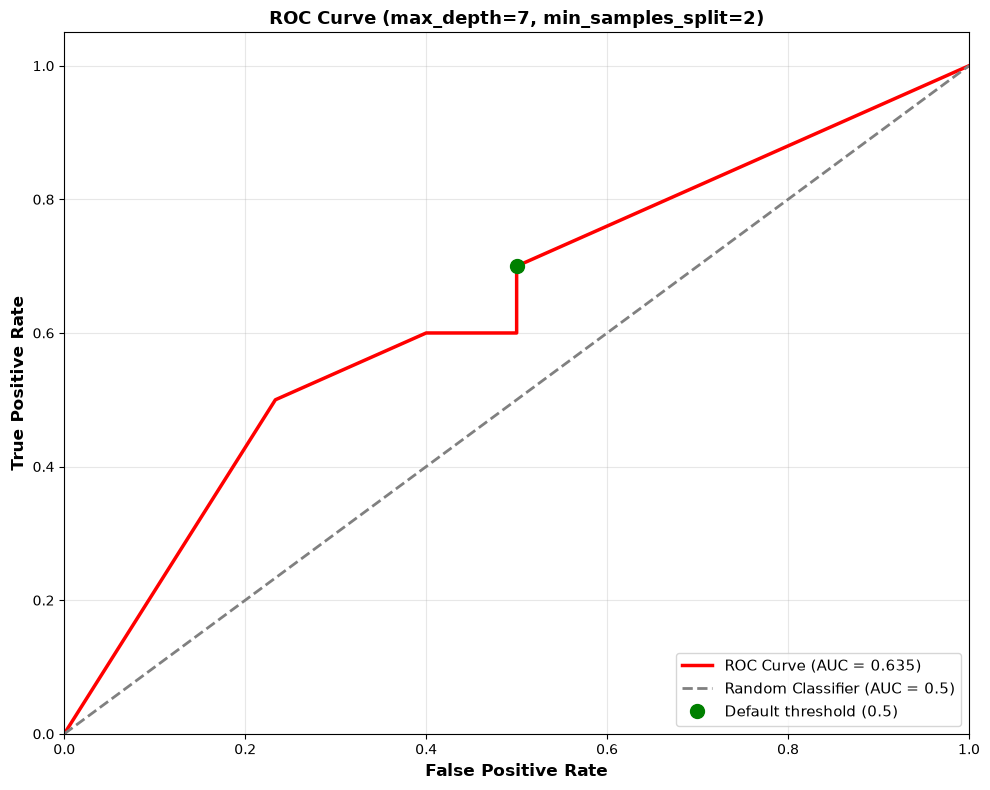


AUC Score: 0.6350
At the default threshold (0.5):
True positive rate: 0.700 (70.0% of resistant correctly classified)
False positive rate: 0.500 (50.0% of susceptible wrongly classified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probabilities for resistance
y_test_proba = best_dt.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='red', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier (AUC = 0.5)')

# Mark the default threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (max_depth={grid_search.best_params_["max_depth"]}, min_samples_split={grid_search.best_params_["min_samples_split"]})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/07_dt_ROC.png", dpi=300)
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At the default threshold (0.5):")
print(f"True positive rate: {tpr[default_idx]:.3f} ({tpr[default_idx]*100:.1f}% of resistant correctly classified)")
print(f"False positive rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptible wrongly classified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.

We will identify which features were used by the best decision tree to classify the samples by looking at the gini importance for each feature. We can access this using *best_dt.feature_importances_*

### **5.1 Get Feature Names**
As before, we don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however, have the names of the clusters, and a list of features associated with each cluster in the file Data/clusters.csv. Let's import the cluster.csv file.

In [15]:
cluster_names = snp_train.columns.values

In [16]:
features_to_cluster = pd.read_csv("Data/clusters.csv")
features_to_cluster.head()

,cluster,snp,cluster_size
0,0,snp__NZ_AP028078.1_1825474_C_T,1
1,1,snp__NZ_AP028077.1_1061328_AGTCGCCGAAGTCGCCGAA...,1
2,2,snp__NZ_AP028077.1_1565260_C_T,1
3,3,snp__NZ_AP028078.1_2219598_T_G,1
4,4,snp__NZ_AP028077.1_72372_G_A,1


### **5.2 Feature Importance**

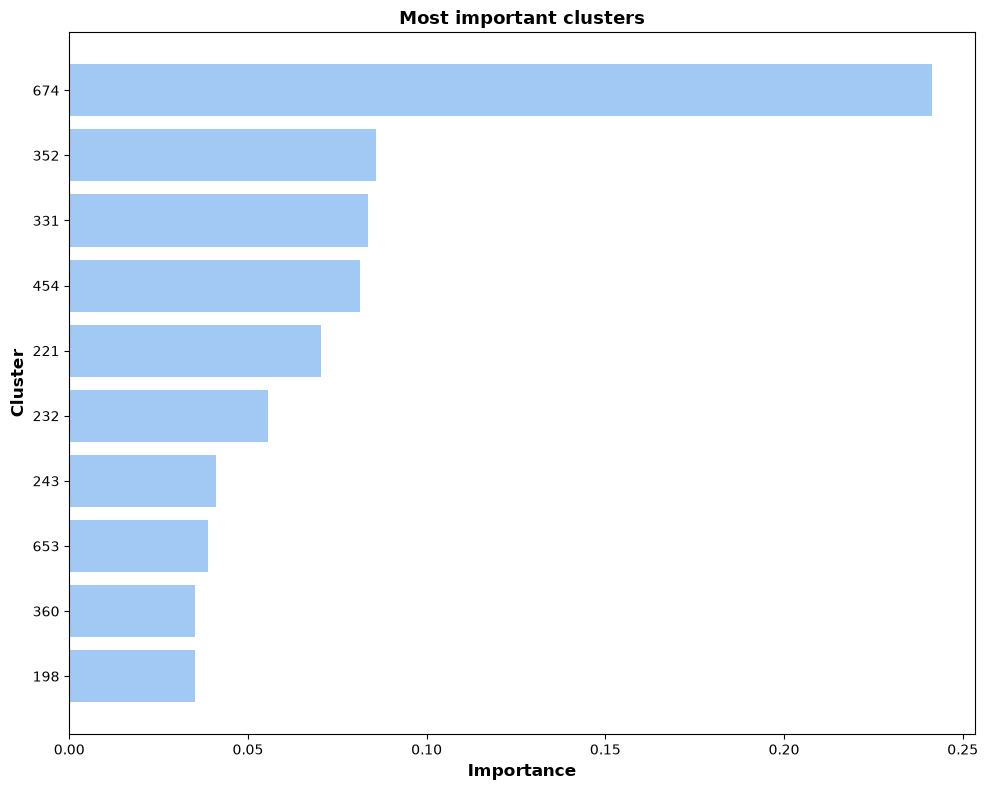

In [17]:
# Get feature importances
feature_importance = best_dt.feature_importances_
feature_importance_df = pd.DataFrame({
    'cluster': cluster_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

# Plot top 10 features (clusters)
plt.figure(figsize=(10, 8))
plt.barh(range(10), feature_importance_df['importance'].head(10))
plt.yticks(range(10), feature_importance_df['cluster'].head(10))
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.ylabel('Cluster', fontsize=12, fontweight='bold')
plt.title('Most important clusters', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Figures/07_dt_feature_importance.png", dpi=300)
plt.show()

In [18]:
top_features = feature_importance_df['cluster'].head(20)
print(features_to_cluster[features_to_cluster.cluster.isin(top_features.index)])

      cluster                                              snp  cluster_size
216        49                   snp__NZ_AP028077.1_1650950_G_A             1
496       198                    snp__NZ_AP028078.1_394891_T_C             1
516       217                   snp__NZ_AP028078.1_1259604_C_A             1
520       221             snp__NZ_AP028077.1_2897021_ACCG_GCCA             1
531       232       snp__NZ_AP028078.1_2619526_T_TGCGAAGCGGCGC             1
542       243                   snp__NZ_AP028077.1_1657496_A_G             1
678       331                    snp__NZ_AP028078.1_795464_G_A             1
692       345               snp__NZ_AP028077.1_1155103_GGT_AAC             1
698       351                   snp__NZ_AP028077.1_2066283_T_C             1
699       352                     snp__NZ_AP028078.1_14421_G_A             1
708       360               snp__NZ_AP028077.1_3403641_ATGC_GT             1
719       370  snp__NZ_AP028077.1_991025_A_ACCACCGCCGTTGCCACCG             1

It will be interesting to compare this list to the features identified with the logistic regression model, and see if some features are common to both models. Let's save these features in a csv file for further analysis.

### **5.3 Save Biomarker results**

In [19]:
# Save biomarker results
features_to_cluster[features_to_cluster.cluster.isin(top_features.index)].to_csv("Results/biomarkers_dt.csv", index=False)

## **6. Save model results**

In [20]:
import csv
import os

# Store results
results = {
    'model': 'Decision Tree',
    'hyperparameters': f"max_depth={grid_search.best_params_['max_depth']}, min_samples_split={grid_search.best_params_['min_samples_split']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = 'Results/model_results.csv'

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: Decision Tree
Hyperparameters: max_depth=7, min_samples_split=2
Test Accuracy: 0.5400
CV Score: 0.6644
